In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

Matplotlib is building the font cache; this may take a moment.


In [22]:
cpi=pd.read_csv("stock_market/data/cpi.csv")
unrate=pd.read_csv("stock_market/data/UNRATE.csv")
fedfunds=pd.read_csv("stock_market/data/DFF.csv")
gdp=pd.read_csv("stock_market/data/gdp.csv")
sp500=pd.read_csv("stock_market/data/s&p.csv")

sp500.head()

,Date,SP500,Dividend,Earnings,Consumer Price Index,Long Interest Rate,Real Price,Real Dividend,Real Earnings,PE10
0,1871-01-01,4.44,0.26,0.4,12.46,5.32,109.05,6.39,9.82,0.0
1,1871-02-01,4.50,0.26,0.4,12.84,5.32,107.25,6.20,9.53,0.0
2,1871-03-01,4.61,0.26,0.4,13.03,5.33,108.27,6.11,9.39,0.0
3,1871-04-01,4.74,0.26,0.4,12.56,5.33,115.54,6.34,9.75,0.0
4,1871-05-01,4.86,0.26,0.4,12.27,5.33,121.22,6.48,9.98,0.0


In [23]:
print("CPI columns:", cpi.columns)
print(cpi.info())

print("GDP columns:", gdp.columns)
print(gdp.info())

print("S&P 500 columns:", sp500.columns)
print(sp500.info())

CPI columns: Index(['observation_date', 'CPALTT01USM657N'], dtype='str')
<class 'pandas.DataFrame'>
RangeIndex: 171 entries, 0 to 170
Data columns (total 2 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   observation_date  171 non-null    str    
 1   CPALTT01USM657N   171 non-null    float64
dtypes: float64(1), str(1)
memory usage: 2.8 KB
None
GDP columns: Index(['observation_date', 'NGDPSAXDCUSQ'], dtype='str')
<class 'pandas.DataFrame'>
RangeIndex: 57 entries, 0 to 56
Data columns (total 2 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   observation_date  57 non-null     str    
 1   NGDPSAXDCUSQ      57 non-null     float64
dtypes: float64(1), str(1)
memory usage: 1.0 KB
None
S&P 500 columns: Index(['Date', 'SP500', 'Dividend', 'Earnings', 'Consumer Price Index',
       'Long Interest Rate', 'Real Price', 'Real Dividend', 'Real Earnings',
       'PE10'],
      dty

In [24]:
cpi["observation_date"] = pd.to_datetime(cpi["observation_date"])
unrate["observation_date"] = pd.to_datetime(unrate["observation_date"])
fedfunds["observation_date"] = pd.to_datetime(fedfunds["observation_date"])
gdp["observation_date"] = pd.to_datetime(gdp["observation_date"])
sp500["Date"] = pd.to_datetime(sp500["Date"])

In [25]:
print("CPI:", cpi["observation_date"].min(), "~", cpi["observation_date"].max())
print("Unemployment:", unrate["observation_date"].min(), "~", unrate["observation_date"].max())
print("Fed Funds:", fedfunds["observation_date"].min(), "~", fedfunds["observation_date"].max())
print("GDP:", gdp["observation_date"].min(), "~", gdp["observation_date"].max())
print("S&P 500:", sp500["Date"].min(), "~", sp500["Date"].max())

CPI: 2010-01-01 00:00:00 ~ 2024-03-01 00:00:00
Unemployment: 2010-01-01 00:00:00 ~ 2024-03-01 00:00:00
Fed Funds: 2010-01-01 00:00:00 ~ 2024-03-01 00:00:00
GDP: 2010-01-01 00:00:00 ~ 2024-01-01 00:00:00
S&P 500: 1871-01-01 00:00:00 ~ 2026-09-01 00:00:00


In [26]:
sp500 = sp500[
    (sp500["Date"] >= "2010-01-01") &
    (sp500["Date"] <= "2024-03-01")
]

print(sp500.head())
print(sp500.tail())

           Date    SP500   Dividend   Earnings  Consumer Price Index  \
1668 2010-01-01  1123.58  22.240000  54.290000                216.69   
1669 2010-02-01  1089.16  22.070000  57.610000                216.74   
1670 2010-03-01  1152.05  21.900000  60.930000                217.63   
1671 2010-04-01  1197.32  21.946667  62.986667                218.01   
1672 2010-05-01  1125.06  21.993333  65.043333                218.18   

      Long Interest Rate  Real Price  Real Dividend  Real Earnings   PE10  
1668                3.73     1587.35          31.42          76.70  20.53  
1669                3.69     1538.34          31.17          81.37  19.92  
1670                3.73     1620.51          30.81          85.71  21.00  
1671                3.85     1681.27          30.82          88.45  21.80  
1672                3.42     1578.58          30.86          91.26  20.48  
           Date    SP500  Dividend  Earnings  Consumer Price Index  \
1834 2023-11-01  4460.06       0.0       

In [ ]:
# changing daily DFF to monthly average DFF

fedfunds["observation_date"] = pd.to_datetime(fedfunds["observation_date"])

fedfunds["month"] = fedfunds["observation_date"].dt.to_period("M")

fedfunds_monthly = fedfunds.groupby("month")["DFF"].mean().reset_index()

print(fedfunds_monthly.head())
print(fedfunds_monthly.tail())


fedfunds_monthly["observation_date"] = (
    fedfunds_monthly["month"].dt.to_timestamp()
)

print(fedfunds_monthly.head())

     month       DFF
0  2010-01  0.110000
1  2010-02  0.126429
2  2010-03  0.164516
3  2010-04  0.198333
4  2010-05  0.200645
       month   DFF
166  2023-11  5.33
167  2023-12  5.33
168  2024-01  5.33
169  2024-02  5.33
170  2024-03  5.33
     month       DFF observation_date
0  2010-01  0.110000       2010-01-01
1  2010-02  0.126429       2010-02-01
2  2010-03  0.164516       2010-03-01
3  2010-04  0.198333       2010-04-01
4  2010-05  0.200645       2010-05-01


In [29]:
print(gdp.head())
print(gdp.tail())

  observation_date  NGDPSAXDCUSQ
0       2010-01-01     3691152.5
1       2010-04-01     3745048.3
2       2010-07-01     3785401.8
3       2010-10-01     3827368.5
4       2011-01-01     3837862.0
   observation_date  NGDPSAXDCUSQ
52       2023-01-01     6804111.3
53       2023-04-01     6882513.8
54       2023-07-01     7018711.5
55       2023-10-01     7106180.5
56       2024-01-01     7177040.3


In [40]:
# Repeating each quarterly GDP value 3 times
gdp_values = gdp["NGDPSAXDCUSQ"].repeat(3).reset_index(drop=True)

# monthly dates
gdp_dates = pd.date_range(start="2010-01-01", periods=len(gdp_values), freq="MS")

# new monthly GDP dataset
gdp_monthly = pd.DataFrame({
    "observation_date": gdp_dates,
    "GDP": gdp_values
})


print(gdp_monthly.head(6))

  observation_date        GDP
0       2010-01-01  3691152.5
1       2010-02-01  3691152.5
2       2010-03-01  3691152.5
3       2010-04-01  3745048.3
4       2010-05-01  3745048.3
5       2010-06-01  3745048.3


In [31]:
# Convert dates to datetime format
cpi["observation_date"] = pd.to_datetime(cpi["observation_date"])
unrate["observation_date"] = pd.to_datetime(unrate["observation_date"])

print(cpi.head())
print(unrate.head())

  observation_date  CPALTT01USM657N
0       2010-01-01         0.341747
1       2010-02-01         0.024921
2       2010-03-01         0.410628
3       2010-04-01         0.173688
4       2010-05-01         0.077520
  observation_date  UNRATE
0       2010-01-01     9.8
1       2010-02-01     9.8
2       2010-03-01     9.9
3       2010-04-01     9.9
4       2010-05-01     9.6


In [33]:
# Rename columns
cpi = cpi.rename(columns={"CPALTT01USM657N": "CPI"})
unrate = unrate.rename(columns={"UNRATE": "Unemployment"})
fedfunds_monthly = fedfunds_monthly.rename(columns={"DFF": "Interest_Rate"})

print(cpi.head())

  observation_date       CPI
0       2010-01-01  0.341747
1       2010-02-01  0.024921
2       2010-03-01  0.410628
3       2010-04-01  0.173688
4       2010-05-01  0.077520


In [ ]:
# Selecting date and S&P 500 columns
sp500 = sp500[["Date", "SP500"]]

# Rename the date column
sp500 = sp500.rename(columns={"Date": "observation_date"})

# Merging all datasets using observation_date
data = sp500.merge(cpi, on="observation_date")
data = data.merge(unrate, on="observation_date")
data = data.merge(fedfunds_monthly[["observation_date", "Interest_Rate"]], on="observation_date")
data = data.merge(gdp_monthly, on="observation_date")


print(data.head())

  observation_date    SP500       CPI  Unemployment  Interest_Rate        GDP
0       2010-01-01  1123.58  0.341747           9.8       0.110000  3691152.5
1       2010-02-01  1089.16  0.024921           9.8       0.126429  3691152.5
2       2010-03-01  1152.05  0.410628           9.9       0.164516  3691152.5
3       2010-04-01  1197.32  0.173688           9.9       0.198333  3745048.3
4       2010-05-01  1125.06  0.077520           9.6       0.200645  3745048.3


In [35]:
print(data.shape)
print(data.isnull().sum())
print(data.dtypes)

(171, 6)
observation_date    0
SP500               0
CPI                 0
Unemployment        0
Interest_Rate       0
GDP                 0
dtype: int64
observation_date    datetime64[us]
SP500                      float64
CPI                        float64
Unemployment               float64
Interest_Rate              float64
GDP                        float64
dtype: object


In [36]:
data.to_csv("cleaned_stock.csv", index=False)

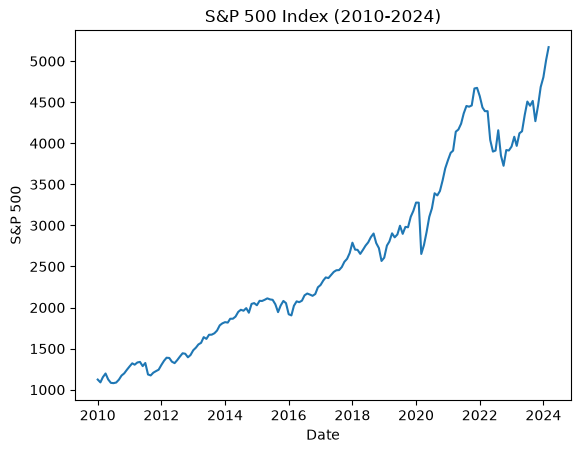

In [ ]:
# line plot of S&P 500
plt.figure()
plt.plot(data["observation_date"], data["SP500"])

plt.title("S&P 500 Index")
plt.xlabel("Date")
plt.ylabel("S&P 500")

plt.show()

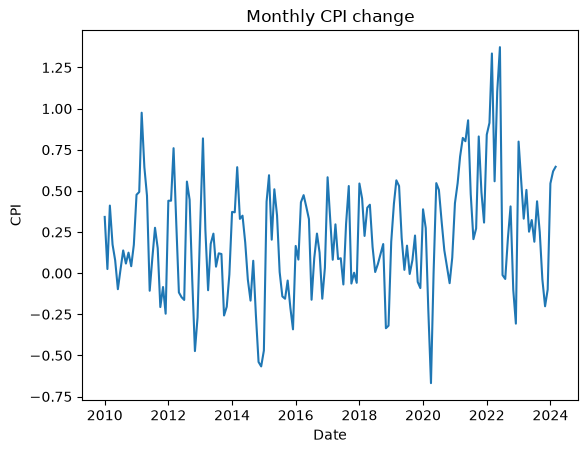

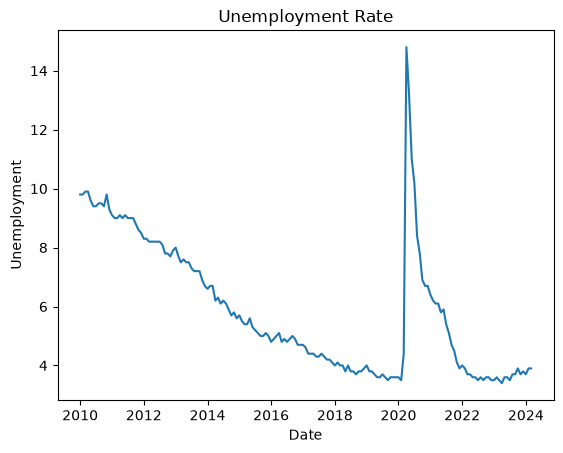

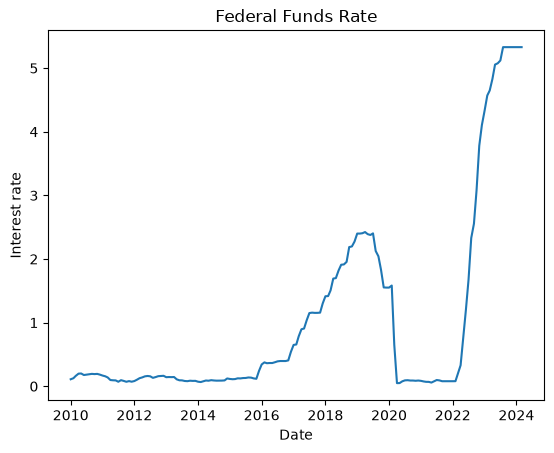

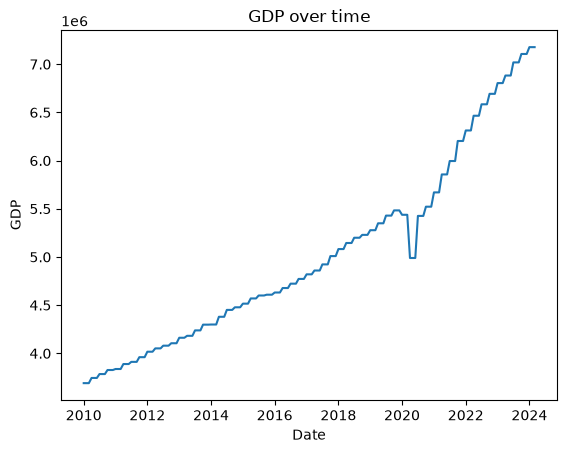

In [42]:
# separate plots for each economic indicator
plt.figure()
plt.plot(data["observation_date"], data["CPI"])
plt.title("Monthly CPI change")
plt.xlabel("Date")
plt.ylabel("CPI")
plt.show()

plt.figure()
plt.plot(data["observation_date"], data["Unemployment"])
plt.title("Unemployment Rate")
plt.xlabel("Date")
plt.ylabel("Unemployment")
plt.show()

plt.figure()
plt.plot(data["observation_date"], data["Interest_Rate"])
plt.title("Federal Funds Rate")
plt.xlabel("Date")
plt.ylabel("Interest rate")
plt.show()

plt.figure()
plt.plot(data["observation_date"], data["GDP"])
plt.title("GDP over time")
plt.xlabel("Date")
plt.ylabel("GDP")
plt.show()

In [43]:
# correlation between econ indicators and S&P 500
correlation = data[["SP500", "CPI", "Unemployment", "Interest_Rate", "GDP"]].corr()

print(correlation)

                  SP500       CPI  Unemployment  Interest_Rate       GDP
SP500          1.000000  0.324661     -0.624661       0.607557  0.968419
CPI            0.324661  1.000000     -0.137495       0.042562  0.266055
Unemployment  -0.624661 -0.137495      1.000000      -0.570601 -0.681655
Interest_Rate  0.607557  0.042562     -0.570601       1.000000  0.750154
GDP            0.968419  0.266055     -0.681655       0.750154  1.000000


In [44]:
# Calculate monthlty returns for S&P 500
data["SP500_Return"] = data["SP500"].pct_change()*100

print(data[["observation_date", "SP500", "SP500_Return"]].head(10))

  observation_date    SP500  SP500_Return
0       2010-01-01  1123.58           NaN
1       2010-02-01  1089.16     -3.063422
2       2010-03-01  1152.05      5.774175
3       2010-04-01  1197.32      3.929517
4       2010-05-01  1125.06     -6.035145
5       2010-06-01  1083.36     -3.706469
6       2010-07-01  1079.80     -0.328607
7       2010-08-01  1087.28      0.692721
8       2010-09-01  1122.08      3.200647
9       2010-10-01  1171.58      4.411450


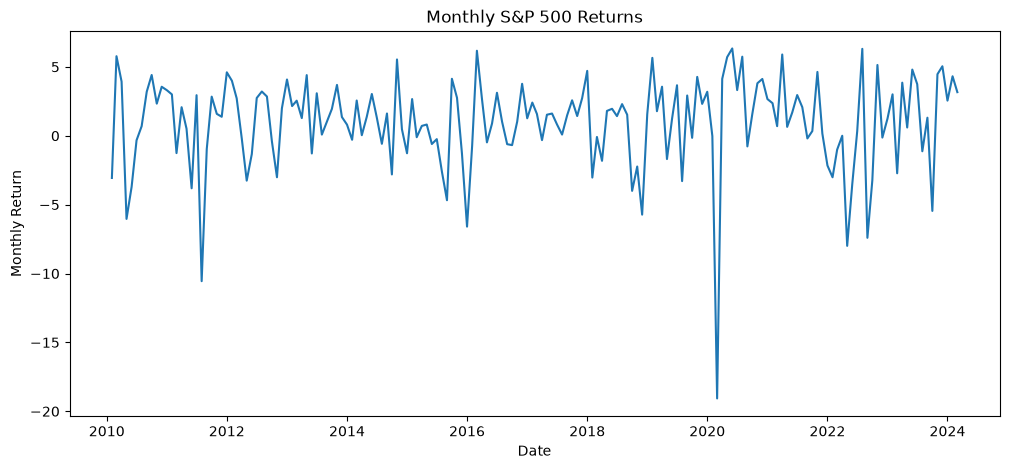

In [ ]:
plt.figure()
plt.plot(data["observation_date"], data["SP500_Return"])

plt.title("Monthly S&P 500 Returns")
plt.xlabel("Date")
plt.ylabel("Monthly Return")

plt.show()

In [46]:
# Finding 5 months with the lowest S&P 500 returns
lowest_returns = data.sort_values("SP500_Return")
print(lowest_returns[["observation_date", "SP500_Return"]].head(5))

    observation_date  SP500_Return
122       2020-03-01    -19.068070
19        2011-08-01    -10.555468
148       2022-05-01     -7.991627
152       2022-09-01     -7.407428
72        2016-01-01     -6.595654


In [47]:
# Calculate correlations using S&P 500 returns
return_correlation = data[["SP500_Return", "CPI", "Unemployment",
                           "Interest_Rate", "GDP"]].corr()
print(return_correlation)

               SP500_Return       CPI  Unemployment  Interest_Rate       GDP
SP500_Return       1.000000  0.054777      0.138253       0.042466  0.002883
CPI                0.054777  1.000000     -0.137495       0.042562  0.266055
Unemployment       0.138253 -0.137495      1.000000      -0.570601 -0.681655
Interest_Rate      0.042466  0.042562     -0.570601       1.000000  0.750154
GDP                0.002883  0.266055     -0.681655       0.750154  1.000000


In [48]:
print(data.tail(10))
print(gdp_monthly.tail(10))

    observation_date        SP500       CPI  Unemployment  Interest_Rate  \
161       2023-06-01  4345.372857  0.322891           3.6       5.076333   
162       2023-07-01  4508.075500  0.190752           3.5       5.120000   
163       2023-08-01  4457.358696  0.436716           3.7       5.330000   
164       2023-09-01  4515.770000  0.248513           3.7       5.330000   
165       2023-10-01  4269.400000 -0.038338           3.9       5.330000   
166       2023-11-01  4460.060000 -0.201514           3.7       5.330000   
167       2023-12-01  4685.050000 -0.099332           3.8       5.330000   
168       2024-01-01  4804.490000  0.544750           3.7       5.330000   
169       2024-02-01  5011.960000  0.618967           3.9       5.330000   
170       2024-03-01  5170.570000  0.646417           3.9       5.330000   

           GDP  SP500_Return  
161  6882513.8      4.804422  
162  7018711.5      3.744273  
163  7018711.5     -1.125021  
164  7018711.5      1.310447  
165  710

In [ ]:
# lagged economic indicators
data["CPI_Lag1"] = data["CPI"].shift(1)
data["Unemployment_Lag1"] = data["Unemployment"].shift(1)
data["Interest_Rate_Lag1"] = data["Interest_Rate"].shift(1)
data["GDP_Lag1"] = data["GDP"].shift(1)

data = data.dropna()
print(data.head())

  observation_date    SP500       CPI  Unemployment  Interest_Rate        GDP  \
1       2010-02-01  1089.16  0.024921           9.8       0.126429  3691152.5   
2       2010-03-01  1152.05  0.410628           9.9       0.164516  3691152.5   
3       2010-04-01  1197.32  0.173688           9.9       0.198333  3745048.3   
4       2010-05-01  1125.06  0.077520           9.6       0.200645  3745048.3   
5       2010-06-01  1083.36 -0.097627           9.4       0.176667  3745048.3   

   SP500_Return  CPI_Lag1  Unemployment_Lag1  Interest_Rate_Lag1   GDP_Lag1  
1     -3.063422  0.341747                9.8            0.110000  3691152.5  
2      5.774175  0.024921                9.8            0.126429  3691152.5  
3      3.929517  0.410628                9.9            0.164516  3691152.5  
4     -6.035145  0.173688                9.9            0.198333  3745048.3  
5     -3.706469  0.077520                9.6            0.200645  3745048.3  


In [52]:
# correlation using lagged econ indicators
lag_correlation = data[["SP500_Return", "CPI_Lag1",
                        "Unemployment_Lag1", "Interest_Rate_Lag1",
                        "GDP_Lag1"]].corr()

print(lag_correlation)

                    SP500_Return  CPI_Lag1  Unemployment_Lag1  \
SP500_Return            1.000000 -0.073006           0.150864   
CPI_Lag1               -0.073006  1.000000          -0.131963   
Unemployment_Lag1       0.150864 -0.131963           1.000000   
Interest_Rate_Lag1      0.030193  0.022325          -0.570961   
GDP_Lag1                0.000727  0.254742          -0.681610   

                    Interest_Rate_Lag1  GDP_Lag1  
SP500_Return                  0.030193  0.000727  
CPI_Lag1                      0.022325  0.254742  
Unemployment_Lag1            -0.570961 -0.681610  
Interest_Rate_Lag1            1.000000  0.741465  
GDP_Lag1                      0.741465  1.000000  


In [ ]:
X = data[["CPI_Lag1", "Unemployment_Lag1",
          "Interest_Rate_Lag1", "GDP_Lag1"]]

y = data["SP500_Return"]

print(X.head())
print(y.head())

# Split the data into training/testing sets
split = int(len(data) * 0.8)

X_train = X[:split]
X_test = X[split:]

y_train = y[:split]
y_test = y[split:]

print(X_train.shape)
print(X_test.shape)

   CPI_Lag1  Unemployment_Lag1  Interest_Rate_Lag1   GDP_Lag1
1  0.341747                9.8            0.110000  3691152.5
2  0.024921                9.8            0.126429  3691152.5
3  0.410628                9.9            0.164516  3691152.5
4  0.173688                9.9            0.198333  3745048.3
5  0.077520                9.6            0.200645  3745048.3
1   -3.063422
2    5.774175
3    3.929517
4   -6.035145
5   -3.706469
Name: SP500_Return, dtype: float64
(136, 4)
(34, 4)


In [ ]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(X_train, y_train)

# Predict S&P 500 returns
y_pred = model.predict(X_test)
print(y_pred)

# actual vspredicted returns
comparison = pd.DataFrame({
    "Actual": y_test,
    "Predicted": y_pred
}, index=y_test.index)

print(comparison)

[2.51731253 2.56077273 2.52690691 2.3926334  2.21521891 2.41462567
 2.23501803 2.14519758 2.34223336 2.29773543 2.20022287 2.39903182
 2.32207504 2.28868673 2.36762122 2.36137113 2.29994286 2.45431404
 2.39849325 2.32807097 2.46766963 2.49299106 2.44155947 2.49166231
 2.56270126 2.56130638 2.70106463 2.77474055 2.77421032 2.98355248
 2.89379179 2.93873015 2.99379593 3.08330599]
       Actual  Predicted
137  1.694880   2.517313
138  2.954432   2.560773
139  2.073773   2.526907
140 -0.194491   2.392633
141  0.341101   2.215219
142  4.633335   2.414626
143  0.158248   2.235018
144 -2.159618   2.145198
145 -3.013567   2.342233
146 -1.008014   2.297735
147  0.000701   2.200223
148 -7.991627   2.399032
149 -3.500018   2.322075
150  0.327854   2.288687
151  6.310087   2.367621
152 -7.407428   2.361371
153 -3.232538   2.299943
154  5.137815   2.454314
155 -0.130380   2.398493
156  1.233917   2.328071
157  3.005265   2.467670
158 -2.723877   2.492991
159  3.852991   2.441559
160  0.599442   2.4

In [59]:
# prediction errors
errors = y_test - y_pred

# abs errors
absolute_errors = abs(errors)

# avg errors
mae = absolute_errors.mean()
print(mae)

# R^2
r2 = model.score(X_test, y_test)

print(r2)

2.9631447588873443
-0.21372120450516707


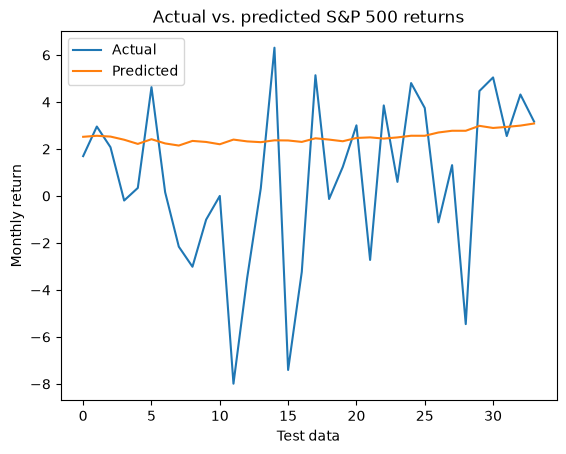

In [60]:
plt.figure()

plt.plot(y_test.values, label="Actual")
plt.plot(y_pred, label="Predicted")

plt.title("Actual vs. predicted S&P 500 returns")
plt.xlabel("Test data")
plt.ylabel("Monthly return")
plt.legend()

plt.show()

In [62]:
# avg return in training data
average_return = y_train.mean()

# predict using the average return
baseline_pred = [average_return] * len(y_test)

# prediction error
baseline_errors = y_test - baseline_pred

# MAE
baseline_mae = abs(baseline_errors).mean()

print( baseline_mae)

2.84744688989654


In [64]:
# prediction errors
errors = y_test - y_pred

# largest prediction errors
print(errors.abs().sort_values(ascending=False).head(5))

#dates and actual/predicted returns
comparison = pd.DataFrame({
    "Date": data["observation_date"].iloc[split:],
    "Actual": y_test,
    "Predicted": y_pred,
    "Error": errors.abs()
})

print(comparison.loc[errors.abs().sort_values(ascending=False).head(5).index])

148    10.390659
152     9.768799
165     8.229980
149     5.822093
153     5.532480
Name: SP500_Return, dtype: float64
          Date    Actual  Predicted      Error
148 2022-05-01 -7.991627   2.399032  10.390659
152 2022-09-01 -7.407428   2.361371   9.768799
165 2023-10-01 -5.455769   2.774210   8.229980
149 2022-06-01 -3.500018   2.322075   5.822093
153 2022-10-01 -3.232538   2.299943   5.532480


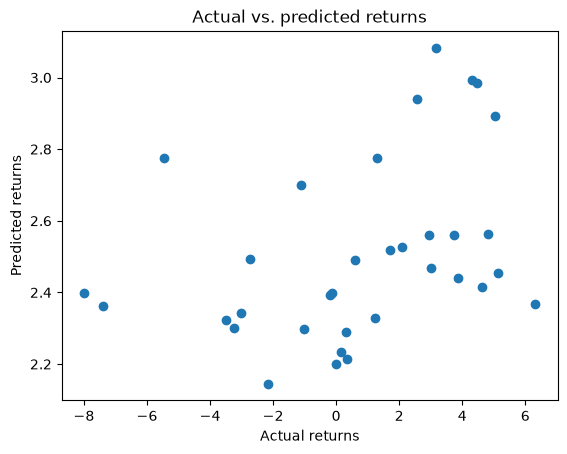

In [65]:
plt.figure()

plt.scatter(y_test, y_pred)

plt.xlabel("Actual returns")
plt.ylabel("Predicted returns")
plt.title("Actual vs. predicted returns")

plt.show()